<a href="https://colab.research.google.com/github/panthangidurgaprasad2792/AI-Fashion-Outfit-Recommendation/blob/main/ML_Project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## 1. Setup and Dataset

In [2]:
# Install required packages once
!pip install -q xgboost shap joblib ipywidgets

from google.colab import drive
drive.mount('/content/drive')


Mounted at /content/drive


In [3]:
# Imports
import os
import re
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import shap
import ipywidgets as widgets

from IPython.display import display, clear_output

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    roc_auc_score,
    precision_score,
    recall_score,
    f1_score,
    average_precision_score,
    precision_recall_curve
)
from xgboost import XGBClassifier


In [4]:
# Load dataset
DATA_PATH = '/content/drive/MyDrive/predictive_maintenance/ai4i_predictive_maintenance_20000.csv'

if not os.path.exists(DATA_PATH):
    raise FileNotFoundError(
        f'Dataset not found at: {DATA_PATH}\n'
        'Update DATA_PATH to the actual CSV location.'
    )

df = pd.read_csv(DATA_PATH)

print('Original shape:', df.shape)
print('Original missing values:', int(df.isna().sum().sum()))


Original shape: (20150, 14)
Original missing values: 2418


## 2. Data Cleaning and Basic Feature Engineering

In [5]:
# Validate required columns and clean the dataset

required_columns = [
    'Type',
    'Air temperature [K]',
    'Process temperature [K]',
    'Rotational speed [rpm]',
    'Torque [Nm]',
    'Tool wear [min]',
    'Machine failure',
    'TWF',
    'HDF',
    'PWF',
    'OSF',
    'RNF'
]

missing_required = [col for col in required_columns if col not in df.columns]

if missing_required:
    raise ValueError(f'Missing required columns: {missing_required}')

# Remove duplicate rows
duplicate_count = df.duplicated().sum()
df = df.drop_duplicates().reset_index(drop=True)

# Convert sensor columns to numeric and fill missing values with medians
sensor_columns = [
    'Air temperature [K]',
    'Process temperature [K]',
    'Rotational speed [rpm]',
    'Torque [Nm]',
    'Tool wear [min]'
]

for column in sensor_columns:
    df[column] = pd.to_numeric(df[column], errors='coerce')
    df[column] = df[column].fillna(df[column].median())

# Clean and encode machine type
type_map = {'L': 0, 'M': 1, 'H': 2}

df['Type'] = (
    df['Type']
    .astype(str)
    .str.strip()
    .str.upper()
    .replace('NAN', np.nan)
)

df['Type'] = df['Type'].fillna(df['Type'].mode()[0])
df['Type_encoded'] = df['Type'].map(type_map)

if df['Type_encoded'].isna().any():
    invalid_types = df.loc[df['Type_encoded'].isna(), 'Type'].unique()
    raise ValueError(f'Unknown machine Type values: {invalid_types}')

# Basic engineered features
df['Power'] = (
    df['Torque [Nm]']
    * df['Rotational speed [rpm]']
    * (2 * np.pi / 60)
)

df['Temp_diff'] = (
    df['Process temperature [K]']
    - df['Air temperature [K]']
)

# These columns are identifiers or the original text category.
df = df.drop(
    columns=['UDI', 'Product ID', 'Type'],
    errors='ignore'
)

print('Duplicate rows removed:', duplicate_count)
print('Cleaned shape:', df.shape)
print('Remaining missing values:', int(df.isna().sum().sum()))


Duplicate rows removed: 120
Cleaned shape: (20030, 14)
Remaining missing values: 0


## 3. Target and Baseline Features

In [6]:
# Define target and baseline feature set

TARGET_COLUMN = 'Machine failure'

failure_type_columns = [
    'TWF',
    'HDF',
    'PWF',
    'OSF',
    'RNF'
]

baseline_features = [
    'Air temperature [K]',
    'Process temperature [K]',
    'Rotational speed [rpm]',
    'Torque [Nm]',
    'Tool wear [min]',
    'Type_encoded',
    'Power',
    'Temp_diff'
]

X_base = df[baseline_features].copy()
y = df[TARGET_COLUMN].astype(int).copy()

# Clean feature names for consistent model/UI usage
X_base.columns = [
    re.sub(r'[\[\]<>]', '', column).strip()
    for column in X_base.columns
]

print('Baseline features:')
print(X_base.columns.tolist())

print('\nTarget distribution:')
print(y.value_counts().sort_index())

print('\nOverall failure rate:', round(y.mean(), 4))


Baseline features:
['Air temperature K', 'Process temperature K', 'Rotational speed rpm', 'Torque Nm', 'Tool wear min', 'Type_encoded', 'Power', 'Temp_diff']

Target distribution:
Machine failure
0    18761
1     1269
Name: count, dtype: int64

Overall failure rate: 0.0634


In [7]:
# Create one reproducible train/test split

X_train_base, X_test_base, y_train, y_test = train_test_split(
    X_base,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print('Training shape:', X_train_base.shape)
print('Testing shape :', X_test_base.shape)
print('Training failure rate:', round(y_train.mean(), 4))
print('Testing failure rate :', round(y_test.mean(), 4))


Training shape: (16024, 8)
Testing shape : (4006, 8)
Training failure rate: 0.0633
Testing failure rate : 0.0634


## 4. Baseline Model Comparison

In [8]:
# Common evaluation function
def calculate_metrics(y_true, y_pred, y_proba):
    tn, fp, fn, tp = confusion_matrix(
        y_true,
        y_pred,
        labels=[0, 1]
    ).ravel()

    return {
        'Accuracy': accuracy_score(y_true, y_pred),
        'Precision': precision_score(y_true, y_pred, zero_division=0),
        'Recall': recall_score(y_true, y_pred, zero_division=0),
        'F1 Score': f1_score(y_true, y_pred, zero_division=0),
        'ROC AUC': roc_auc_score(y_true, y_proba),
        'PR AUC': average_precision_score(y_true, y_proba),
        'FPR': fp / (fp + tn) if (fp + tn) > 0 else 0.0,
        'FNR': fn / (fn + tp) if (fn + tp) > 0 else 0.0
    }


# Logistic Regression requires scaled features
scaler_base = StandardScaler()

X_train_scaled = scaler_base.fit_transform(X_train_base)
X_test_scaled = scaler_base.transform(X_test_base)

logistic_model = LogisticRegression(
    class_weight='balanced',
    max_iter=1000,
    random_state=42
)

logistic_model.fit(X_train_scaled, y_train)

logistic_predictions = logistic_model.predict(X_test_scaled)
logistic_probabilities = logistic_model.predict_proba(X_test_scaled)[:, 1]


# Random Forest does not require scaling
random_forest_model = RandomForestClassifier(
    n_estimators=200,
    class_weight='balanced',
    random_state=42,
    n_jobs=-1
)

random_forest_model.fit(X_train_base, y_train)

random_forest_predictions = random_forest_model.predict(X_test_base)
random_forest_probabilities = (
    random_forest_model.predict_proba(X_test_base)[:, 1]
)


# Baseline XGBoost
baseline_scale_pos_weight = (
    (y_train == 0).sum()
    / max((y_train == 1).sum(), 1)
)

baseline_xgb_model = XGBClassifier(
    n_estimators=250,
    max_depth=5,
    learning_rate=0.05,
    subsample=0.85,
    colsample_bytree=0.85,
    scale_pos_weight=baseline_scale_pos_weight,
    objective='binary:logistic',
    eval_metric='logloss',
    tree_method='hist',
    n_jobs=-1,
    random_state=42
)

baseline_xgb_model.fit(X_train_base, y_train)

baseline_xgb_predictions = baseline_xgb_model.predict(X_test_base)
baseline_xgb_probabilities = (
    baseline_xgb_model.predict_proba(X_test_base)[:, 1]
)


# Compare all baseline models
baseline_comparison = pd.DataFrame([
    {
        'Model': 'Logistic Regression',
        **calculate_metrics(
            y_test,
            logistic_predictions,
            logistic_probabilities
        )
    },
    {
        'Model': 'Random Forest',
        **calculate_metrics(
            y_test,
            random_forest_predictions,
            random_forest_probabilities
        )
    },
    {
        'Model': 'XGBoost',
        **calculate_metrics(
            y_test,
            baseline_xgb_predictions,
            baseline_xgb_probabilities
        )
    }
])

display(baseline_comparison.round(4))


,Model,Accuracy,Precision,Recall,F1 Score,ROC AUC,PR AUC,FPR,FNR
0,Logistic Regression,0.7788,0.1967,0.8071,0.3164,0.8704,0.4425,0.2231,0.1929
1,Random Forest,0.9890,0.9605,0.8622,0.9087,0.9867,0.9499,0.0024,0.1378
2,XGBoost,0.9688,0.6925,0.9134,0.7878,0.9805,0.9144,0.0275,0.0866


## 5. Deterioration Feature Engineering

In [9]:
# Calculate thresholds ONLY from training rows
# to keep feature engineering consistent with the training data.

training_indices = X_train_base.index

torque_q75 = df.loc[
    training_indices,
    'Torque [Nm]'
].quantile(0.75)

temp_diff_q75 = df.loc[
    training_indices,
    'Temp_diff'
].quantile(0.75)

tool_wear_max = df.loc[
    training_indices,
    'Tool wear [min]'
].max()


# Create deterioration-related features
df['Temp_ratio'] = (
    df['Process temperature [K]']
    / df['Air temperature [K]'].replace(0, np.nan)
)

df['Torque_RPM'] = (
    df['Torque [Nm]']
    * df['Rotational speed [rpm]']
)

df['Tool_wear_ratio'] = (
    df['Tool wear [min]']
    / max(tool_wear_max, 1e-9)
)

df['High_tool_wear'] = (
    df['Tool wear [min]'] > 200
).astype(int)

df['High_torque'] = (
    df['Torque [Nm]'] > torque_q75
).astype(int)

df['High_temp_diff'] = (
    df['Temp_diff'] > temp_diff_q75
).astype(int)

df['Temp_ratio'] = df['Temp_ratio'].fillna(1.0)


deterioration_features = [
    'Air temperature [K]',
    'Process temperature [K]',
    'Rotational speed [rpm]',
    'Torque [Nm]',
    'Tool wear [min]',
    'Type_encoded',
    'Power',
    'Temp_diff',
    'Temp_ratio',
    'Torque_RPM',
    'Tool_wear_ratio',
    'High_tool_wear',
    'High_torque',
    'High_temp_diff'
]

X_deterioration = df[deterioration_features].copy()

X_deterioration.columns = [
    re.sub(r'[\[\]<>]', '', column).strip()
    for column in X_deterioration.columns
]

# Use the exact same train/test indices as the baseline split
X_train_det = X_deterioration.loc[X_train_base.index].copy()
X_test_det = X_deterioration.loc[X_test_base.index].copy()

y_train_det = y.loc[X_train_base.index].copy()
y_test_det = y.loc[X_test_base.index].copy()

print('Deterioration feature count:', X_deterioration.shape[1])
print('\nDeterioration features:')
print(X_deterioration.columns.tolist())


Deterioration feature count: 14

Deterioration features:
['Air temperature K', 'Process temperature K', 'Rotational speed rpm', 'Torque Nm', 'Tool wear min', 'Type_encoded', 'Power', 'Temp_diff', 'Temp_ratio', 'Torque_RPM', 'Tool_wear_ratio', 'High_tool_wear', 'High_torque', 'High_temp_diff']


## 6. Train XGBoost with Deterioration Features

In [10]:
# Train the final feature-engineered XGBoost model

deterioration_scale_pos_weight = (
    (y_train_det == 0).sum()
    / max((y_train_det == 1).sum(), 1)
)

deterioration_xgb_model = XGBClassifier(
    n_estimators=200,
    max_depth=5,
    learning_rate=0.05,
    subsample=0.80,
    colsample_bytree=0.80,
    scale_pos_weight=deterioration_scale_pos_weight,
    objective='binary:logistic',
    eval_metric='logloss',
    tree_method='hist',
    n_jobs=-1,
    random_state=42
)

deterioration_xgb_model.fit(
    X_train_det,
    y_train_det
)

deterioration_probabilities = (
    deterioration_xgb_model
    .predict_proba(X_test_det)[:, 1]
)

deterioration_predictions = (
    deterioration_probabilities >= 0.50
).astype(int)

print('Deterioration XGBoost trained successfully.')


Deterioration XGBoost trained successfully.


## 7. Baseline vs Deterioration Model Comparison

MODEL COMPARISON


,Model,Accuracy,Precision,Recall,F1 Score,ROC AUC,PR AUC,FPR,FNR
0,Original XGBoost,0.9688,0.6925,0.9134,0.7878,0.9805,0.9144,0.0275,0.0866
1,XGBoost + Deterioration Features,0.9678,0.6812,0.9252,0.7846,0.9815,0.9168,0.0293,0.0748


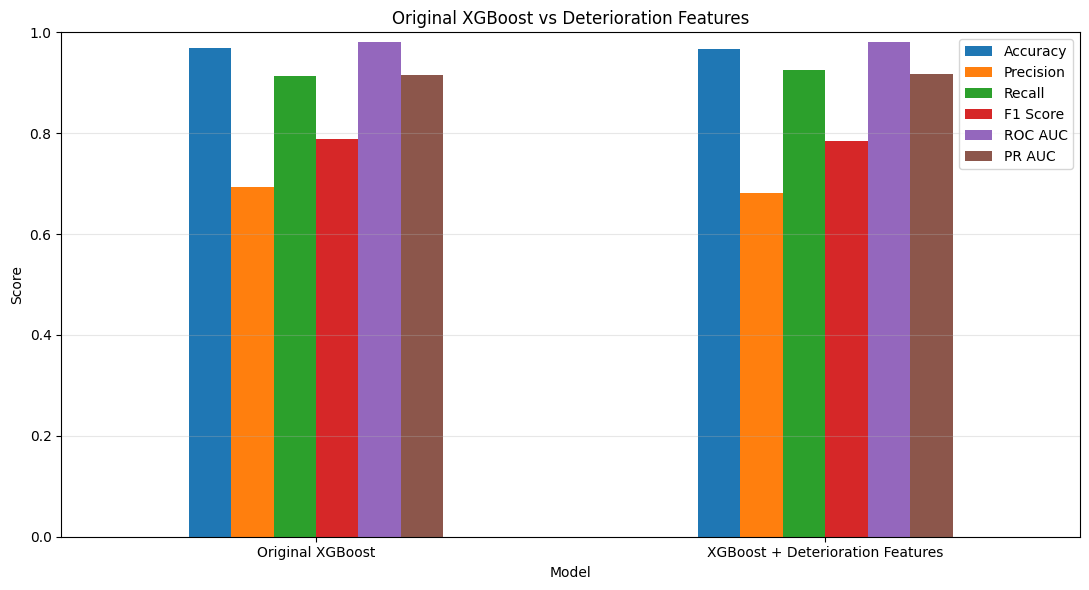

In [11]:
# Compare the original XGBoost with the feature-engineered XGBoost

baseline_xgb_metrics = calculate_metrics(
    y_test,
    baseline_xgb_predictions,
    baseline_xgb_probabilities
)

deterioration_xgb_metrics = calculate_metrics(
    y_test_det,
    deterioration_predictions,
    deterioration_probabilities
)

model_comparison = pd.DataFrame([
    {
        'Model': 'Original XGBoost',
        **baseline_xgb_metrics
    },
    {
        'Model': 'XGBoost + Deterioration Features',
        **deterioration_xgb_metrics
    }
])

print('=' * 70)
print('MODEL COMPARISON')
print('=' * 70)

display(model_comparison.round(4))


# Plot the main metrics
comparison_plot = model_comparison.set_index('Model')[
    [
        'Accuracy',
        'Precision',
        'Recall',
        'F1 Score',
        'ROC AUC',
        'PR AUC'
    ]
]

ax = comparison_plot.plot(
    kind='bar',
    figsize=(11, 6)
)

ax.set_title('Original XGBoost vs Deterioration Features')
ax.set_xlabel('Model')
ax.set_ylabel('Score')
ax.set_ylim(0, 1)
ax.tick_params(axis='x', rotation=0)
ax.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()


## 8. Select the Final Decision Threshold

In [12]:
# Search for a threshold that keeps Recall >= 0.70
# while minimizing False Positive Rate.

threshold_results = []

for threshold in np.arange(0.10, 0.91, 0.01):
    predictions = (
        deterioration_probabilities >= threshold
    ).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_test_det,
        predictions,
        labels=[0, 1]
    ).ravel()

    precision = precision_score(
        y_test_det,
        predictions,
        zero_division=0
    )

    recall = recall_score(
        y_test_det,
        predictions,
        zero_division=0
    )

    f1 = f1_score(
        y_test_det,
        predictions,
        zero_division=0
    )

    fpr = (
        fp / (fp + tn)
        if (fp + tn) > 0
        else 0.0
    )

    fnr = (
        fn / (fn + tp)
        if (fn + tp) > 0
        else 0.0
    )

    threshold_results.append({
        'Threshold': round(float(threshold), 2),
        'Precision': precision,
        'Recall': recall,
        'F1 Score': f1,
        'FPR': fpr,
        'FNR': fnr
    })

threshold_results_df = pd.DataFrame(threshold_results)

valid_thresholds = threshold_results_df[
    threshold_results_df['Recall'] >= 0.70
]

if not valid_thresholds.empty:
    best_threshold_row = valid_thresholds.loc[
        valid_thresholds['FPR'].idxmin()
    ]

    threshold_selection_reason = (
        'Minimum FPR among thresholds with Recall >= 0.70'
    )
else:
    best_threshold_row = threshold_results_df.loc[
        threshold_results_df['F1 Score'].idxmax()
    ]

    threshold_selection_reason = (
        'Highest F1 Score because Recall >= 0.70 was not achieved'
    )

best_threshold = float(best_threshold_row['Threshold'])

final_predictions = (
    deterioration_probabilities >= best_threshold
).astype(int)

print('=' * 60)
print('OPTIMIZED THRESHOLD')
print('=' * 60)
print('Selected threshold:', round(best_threshold, 2))
print('Reason:', threshold_selection_reason)
print('Precision:', round(best_threshold_row['Precision'], 4))
print('Recall:', round(best_threshold_row['Recall'], 4))
print('F1 Score:', round(best_threshold_row['F1 Score'], 4))
print('FPR:', round(best_threshold_row['FPR'], 4))
print('FNR:', round(best_threshold_row['FNR'], 4))

print('\nThresholds near the selected value:')
nearby_thresholds = threshold_results_df[
    threshold_results_df['Threshold'].between(
        best_threshold - 0.05,
        best_threshold + 0.05
    )
]

display(nearby_thresholds.round(4))


OPTIMIZED THRESHOLD
Selected threshold: 0.86
Reason: Minimum FPR among thresholds with Recall >= 0.70
Precision: 0.9524
Recall: 0.7874
F1 Score: 0.8621
FPR: 0.0027
FNR: 0.2126

Thresholds near the selected value:


,Threshold,Precision,Recall,F1 Score,FPR,FNR
71,0.81,0.9318,0.8071,0.8650,0.0040,0.1929
72,0.82,0.9309,0.7953,0.8577,0.0040,0.2047
73,0.83,0.9352,0.7953,0.8596,0.0037,0.2047
74,0.84,0.9393,0.7913,0.8590,0.0035,0.2087
75,0.85,0.9437,0.7913,0.8608,0.0032,0.2087
76,0.86,0.9524,0.7874,0.8621,0.0027,0.2126
77,0.87,0.9517,0.7756,0.8547,0.0027,0.2244
78,0.88,0.9517,0.7756,0.8547,0.0027,0.2244
79,0.89,0.9507,0.7598,0.8446,0.0027,0.2402
80,0.90,0.9497,0.7441,0.8344,0.0027,0.2559


## 9. Final Model Evaluation

=== FINAL MODEL: XGBoost + Deterioration Features ===
              precision    recall  f1-score   support

      Normal       0.99      1.00      0.99      3752
     Failure       0.95      0.79      0.86       254

    accuracy                           0.98      4006
   macro avg       0.97      0.89      0.93      4006
weighted avg       0.98      0.98      0.98      4006

ROC-AUC: 0.9815
PR-AUC : 0.9168


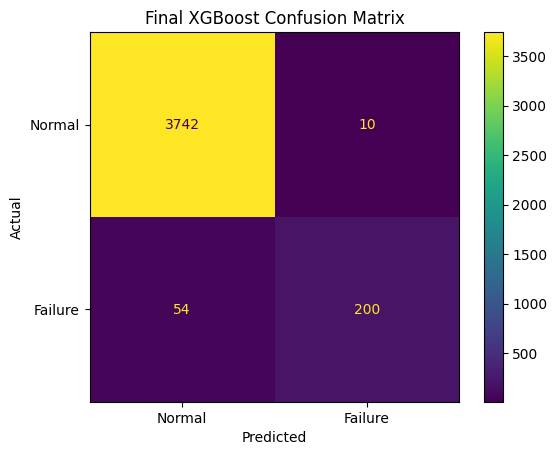

In [13]:
# Set the final model variables
final_model = deterioration_xgb_model
final_probabilities = deterioration_probabilities
final_predictions = final_predictions

print('=== FINAL MODEL: XGBoost + Deterioration Features ===')

print(
    classification_report(
        y_test_det,
        final_predictions,
        target_names=['Normal', 'Failure'],
        zero_division=0
    )
)

print(
    'ROC-AUC:',
    round(roc_auc_score(y_test_det, final_probabilities), 4)
)

print(
    'PR-AUC :',
    round(
        average_precision_score(
            y_test_det,
            final_probabilities
        ),
        4
    )
)


# Confusion matrix
confusion_matrix_values = confusion_matrix(
    y_test_det,
    final_predictions,
    labels=[0, 1]
)

confusion_display = ConfusionMatrixDisplay(
    confusion_matrix=confusion_matrix_values,
    display_labels=['Normal', 'Failure']
)

confusion_display.plot()
plt.title('Final XGBoost Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()


## 10. Precision-Recall Curve

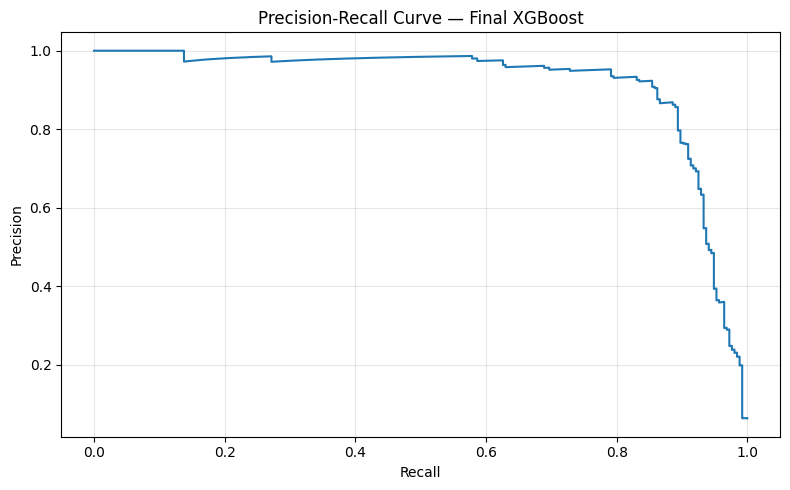

In [14]:
precision_values, recall_values, _ = precision_recall_curve(
    y_test_det,
    final_probabilities
)

plt.figure(figsize=(8, 5))
plt.plot(recall_values, precision_values)
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision-Recall Curve — Final XGBoost')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


## 11. SHAP Explainability

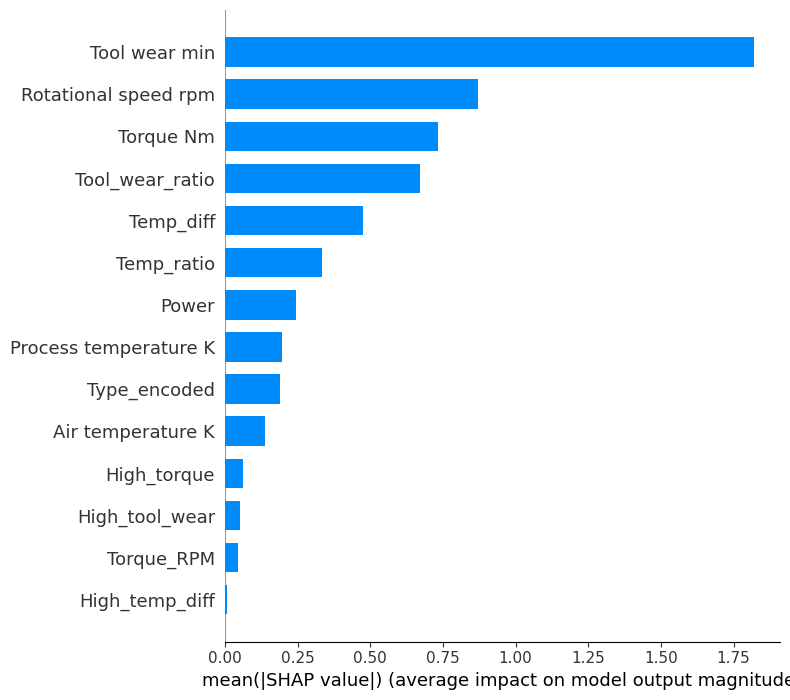

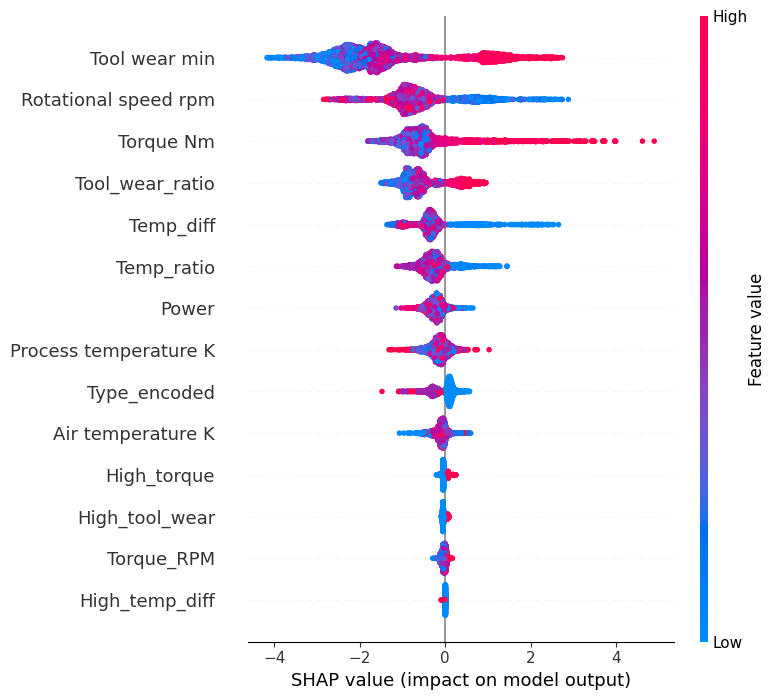

In [15]:
# Global SHAP explanation
shap_explainer = shap.TreeExplainer(final_model)
shap_values = shap_explainer.shap_values(X_test_det)

# Global feature importance
shap.summary_plot(
    shap_values,
    X_test_det,
    plot_type='bar',
    show=True
)

# Feature impact direction and magnitude
shap.summary_plot(
    shap_values,
    X_test_det,
    show=True
)


Test sample position: 15
Actual value: 1
Predicted value: 1
Failure probability: 97.60%


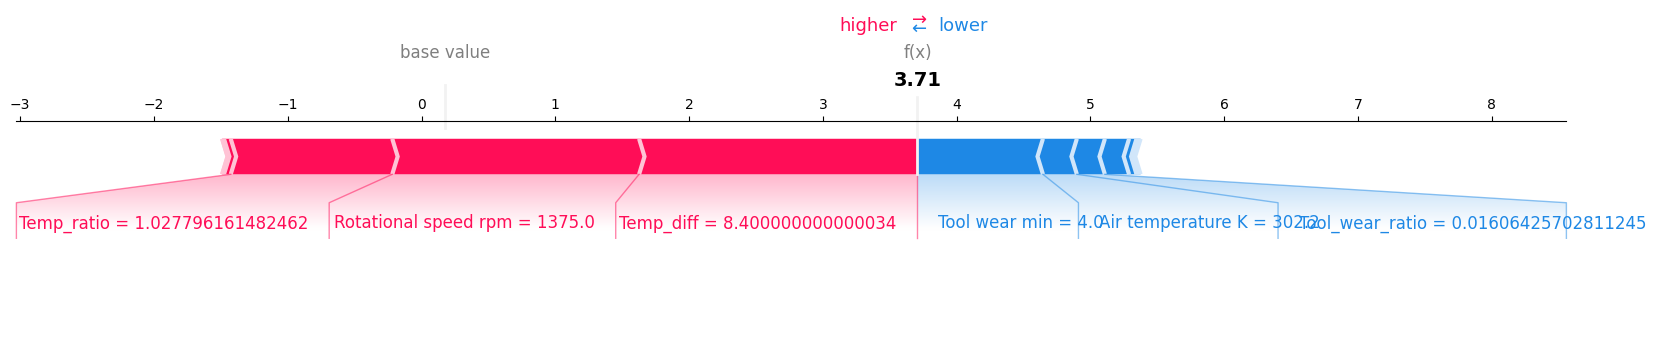

In [16]:
# Local SHAP explanation for the first predicted failure

predicted_failure_positions = np.where(final_predictions == 1)[0]

if len(predicted_failure_positions) > 0:
    sample_position = int(predicted_failure_positions[0])

    print('Test sample position:', sample_position)
    print('Actual value:', int(y_test_det.iloc[sample_position]))
    print('Predicted value:', int(final_predictions[sample_position]))
    print(
        'Failure probability:',
        f'{final_probabilities[sample_position]:.2%}'
    )

    shap.force_plot(
        shap_explainer.expected_value,
        shap_values[sample_position],
        X_test_det.iloc[sample_position],
        matplotlib=True
    )

    plt.show()
else:
    print('No failure predictions were found at the selected threshold.')


## 12. Failure-Type Distribution

,Failure Type,Count
0,TWF,23
1,HDF,59
2,PWF,8
3,OSF,126
4,RNF,1


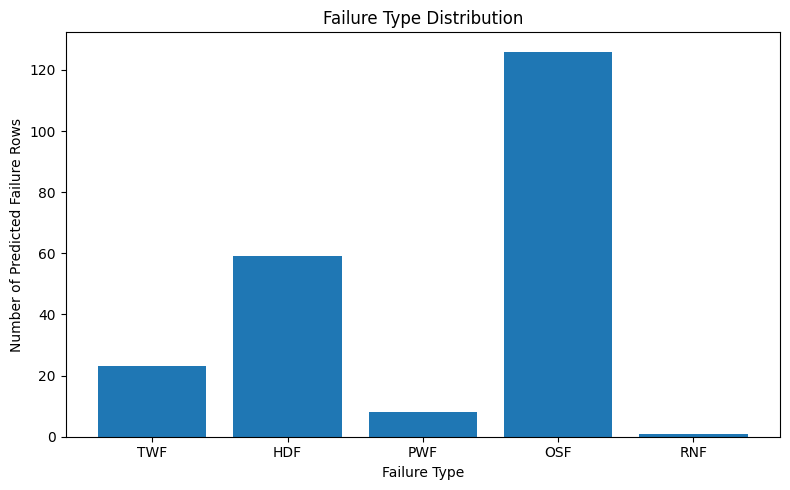

In [17]:
# Count failure-mode indicators among rows predicted as failures

predicted_failure_indices = y_test_det.index[
    final_predictions == 1
]

failure_type_counts = {
    failure_type: int(
        df.loc[predicted_failure_indices, failure_type].sum()
    )
    for failure_type in failure_type_columns
}

failure_type_df = pd.DataFrame(
    list(failure_type_counts.items()),
    columns=['Failure Type', 'Count']
)

display(failure_type_df)

plt.figure(figsize=(8, 5))
plt.bar(
    failure_type_df['Failure Type'],
    failure_type_df['Count']
)
plt.xlabel('Failure Type')
plt.ylabel('Number of Predicted Failure Rows')
plt.title('Failure Type Distribution')
plt.tight_layout()
plt.show()


## 13. Save the Trained Model Package

In [18]:
# Save everything required for later prediction/deployment

model_package = {
    'model': final_model,
    'threshold': best_threshold,
    'feature_columns': X_deterioration.columns.tolist(),
    'type_map': type_map,
    'tool_wear_max': float(tool_wear_max),
    'torque_q75': float(torque_q75),
    'temp_diff_q75': float(temp_diff_q75)
}

MODEL_PATH = '/content/predictive_maintenance_model.pkl'

joblib.dump(model_package, MODEL_PATH)

print('Model package saved to:')
print(MODEL_PATH)


Model package saved to:
/content/predictive_maintenance_model.pkl


## 14. Interactive Prediction UI

In [19]:
# Interactive prediction UI
# This is the only prediction UI in the notebook.

air_temperature_slider = widgets.FloatSlider(
    value=300.0,
    min=295.0,
    max=305.0,
    step=0.1,
    description='Air Temp (K):'
)

process_temperature_slider = widgets.FloatSlider(
    value=310.0,
    min=300.0,
    max=320.0,
    step=0.1,
    description='Process Temp (K):'
)

rpm_slider = widgets.IntSlider(
    value=1500,
    min=500,
    max=3000,
    step=50,
    description='RPM:'
)

torque_slider = widgets.FloatSlider(
    value=40.0,
    min=10.0,
    max=80.0,
    step=1.0,
    description='Torque (Nm):'
)

tool_wear_slider = widgets.IntSlider(
    value=100,
    min=0,
    max=250,
    step=5,
    description='Tool Wear:'
)

machine_type_dropdown = widgets.Dropdown(
    options=[
        ('Low (L)', 0),
        ('Medium (M)', 1),
        ('High (H)', 2)
    ],
    value=1,
    description='Type:'
)

predict_button = widgets.Button(
    description='Predict Failure',
    button_style='primary'
)

prediction_output = widgets.Output()


def build_prediction_input(
    air_temperature,
    process_temperature,
    rpm,
    torque,
    tool_wear,
    machine_type
):
    # Derived features must match the model's training features exactly.
    power = (
        torque
        * rpm
        * (2 * np.pi / 60)
    )

    temperature_difference = (
        process_temperature
        - air_temperature
    )

    temperature_ratio = (
        process_temperature
        / air_temperature
        if air_temperature != 0
        else 1.0
    )

    torque_rpm = torque * rpm

    tool_wear_ratio = (
        tool_wear
        / max(tool_wear_max, 1e-9)
    )

    high_tool_wear = int(tool_wear > 200)
    high_torque = int(torque > torque_q75)
    high_temperature_difference = int(
        temperature_difference > temp_diff_q75
    )

    input_values = [[
        air_temperature,
        process_temperature,
        rpm,
        torque,
        tool_wear,
        machine_type,
        power,
        temperature_difference,
        temperature_ratio,
        torque_rpm,
        tool_wear_ratio,
        high_tool_wear,
        high_torque,
        high_temperature_difference
    ]]

    return pd.DataFrame(
        input_values,
        columns=X_deterioration.columns
    )


def predict_machine_failure(_):
    with prediction_output:
        clear_output(wait=True)

        input_data = build_prediction_input(
            air_temperature_slider.value,
            process_temperature_slider.value,
            rpm_slider.value,
            torque_slider.value,
            tool_wear_slider.value,
            machine_type_dropdown.value
        )

        probability = final_model.predict_proba(
            input_data
        )[0, 1]

        prediction = int(
            probability >= best_threshold
        )

        if prediction == 1:
            print('⚠️ MACHINE FAILURE RISK')
        else:
            print('✅ MACHINE OPERATING NORMALLY')

        print(f'Failure Probability: {probability:.2%}')
        print(f'Decision Threshold: {best_threshold:.2f}')


predict_button.on_click(predict_machine_failure)

display(
    air_temperature_slider,
    process_temperature_slider,
    rpm_slider,
    torque_slider,
    tool_wear_slider,
    machine_type_dropdown,
    predict_button,
    prediction_output
)


FloatSlider(value=300.0, description='Air Temp (K):', max=305.0, min=295.0)

FloatSlider(value=310.0, description='Process Temp (K):', max=320.0, min=300.0)

IntSlider(value=1500, description='RPM:', max=3000, min=500, step=50)

FloatSlider(value=40.0, description='Torque (Nm):', max=80.0, min=10.0, step=1.0)

IntSlider(value=100, description='Tool Wear:', max=250, step=5)

Dropdown(description='Type:', index=1, options=(('Low (L)', 0), ('Medium (M)', 1), ('High (H)', 2)), value=1)

Button(button_style='primary', description='Predict Failure', style=ButtonStyle())

Output()